# Task-5 Week-3.

**Dataset :-** 'Admission_Prediction.csv'

**Objective :-Apply advanced regression diagnostic techniques, including residual analysis, multicollinearity checks, and homoscedasticity validation, to rigorously test model assumptions for accurate admissions prediction

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

In [3]:
# Load the dataset 
df = pd.read_csv("Admission_Prediction.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst Five Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 14)

Column Names:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Year', 'Application_Date', 'University_Name', 'region', 'Admission Status']

First Five Rows:


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,2022-01-03,Indian Institute of Technology Bombay,West,Rejected
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,2022-01-09,Indian Institute of Technology Delhi,North,Rejected
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,2022-01-12,Indian Institute of Technology Delhi,North,Rejected
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,2022-01-13,Indian Institute of Technology Delhi,North,Accepted
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,2022-01-14,Indian Institute of Technology Delhi,North,Rejected



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         1000 non-null   int64  
 1   GRE Score          1000 non-null   int64  
 2   TOEFL Score        1000 non-null   int64  
 3   University Rating  1000 non-null   int64  
 4   SOP                1000 non-null   float64
 5   LOR                1000 non-null   float64
 6   CGPA               1000 non-null   float64
 7   Research           1000 non-null   int64  
 8   Chance of Admit    1000 non-null   float64
 9   Year               1000 non-null   int64  
 10  Application_Date   1000 non-null   object 
 11  University_Name    1000 non-null   object 
 12  region             1000 non-null   object 
 13  Admission Status   1000 non-null   object 
dtypes: float64(4), int64(6), object(4)
memory usage: 109.5+ KB


In [4]:
# Cleaning and prepartion.

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Summary:")
print(df["Chance of Admit"].describe())

Missing Values:
Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
Year                 0
Application_Date     0
University_Name      0
region               0
Admission Status     0
dtype: int64

Duplicate Rows: 0

Target Summary:
count    1000.00000
mean        0.71777
std         0.14591
min         0.32000
25%         0.63750
50%         0.72000
75%         0.82000
max         0.97000
Name: Chance of Admit, dtype: float64


In [5]:
features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

target = "Chance of Admit"

data = df[features + [target]].copy()

# Convert selected columns to numeric if needed
for col in features + [target]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Replace infinite values and remove incomplete rows
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna()

X = data[features]
y = data[target]

print("Cleaned Dataset Shape:", data.shape)
print("Number of Predictors:", len(features))
print("Target Variable:", target)

Cleaned Dataset Shape: (1000, 8)
Number of Predictors: 7
Target Variable: Chance of Admit


In [6]:
# Build the multiple linear regression model

# Add the intercept
X_ols = sm.add_constant(X)

# Fit the regression model
model = sm.OLS(y, X_ols).fit()

# Display complete regression results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.221
Model:                            OLS   Adj. R-squared:                  0.215
Method:                 Least Squares   F-statistic:                     40.15
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           7.07e-50
Time:                        02:21:41   Log-Likelihood:                 631.06
No. Observations:                1000   AIC:                            -1246.
Df Residuals:                     992   BIC:                            -1207.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.5316      0.11

In [7]:
# Perform residual analysis

# Calculate predicted values and residuals
data["Predicted"] = model.predict(X_ols)
data["Residual"] = y - data["Predicted"]

print(data[["Chance of Admit", "Predicted", "Residual"]].head())

print("\nMean Residual:", data["Residual"].mean())
print("Residual Standard Deviation:", data["Residual"].std())

   Chance of Admit  Predicted  Residual
0             0.57   0.709270 -0.139270
1             0.65   0.624406  0.025594
2             0.71   0.666463  0.043537
3             0.75   0.657030  0.092970
4             0.56   0.673007 -0.113007

Mean Residual: 4.67847982577041e-16
Residual Standard Deviation: 0.12879930187382377


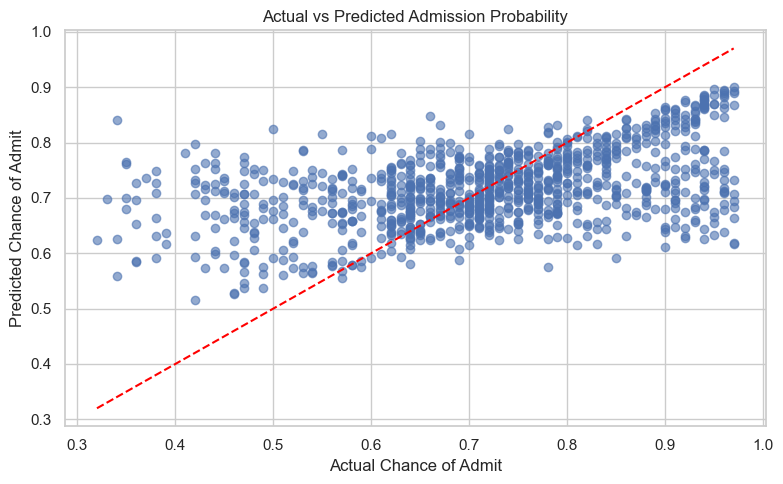

In [8]:
# Plot actual versus predicted values

plt.figure(figsize=(8, 5))

plt.scatter(
    data["Chance of Admit"],
    data["Predicted"],
    alpha=0.6
)

minimum = min(data["Chance of Admit"].min(),
              data["Predicted"].min())
maximum = max(data["Chance of Admit"].max(),
              data["Predicted"].max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Chance of Admit")
plt.ylabel("Predicted Chance of Admit")
plt.title("Actual vs Predicted Admission Probability")
plt.tight_layout()
plt.show()

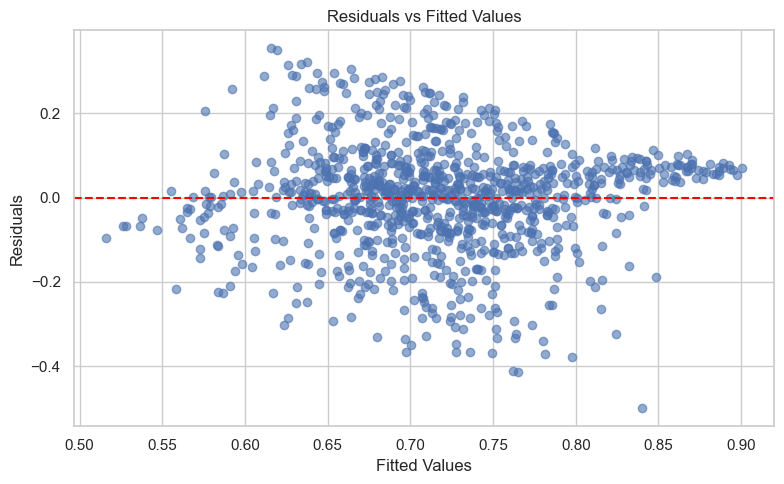

In [9]:
# Plot residuals against fitted values

plt.figure(figsize=(8, 5))

plt.scatter(
    data["Predicted"],
    data["Residual"],
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")
plt.tight_layout()
plt.show()

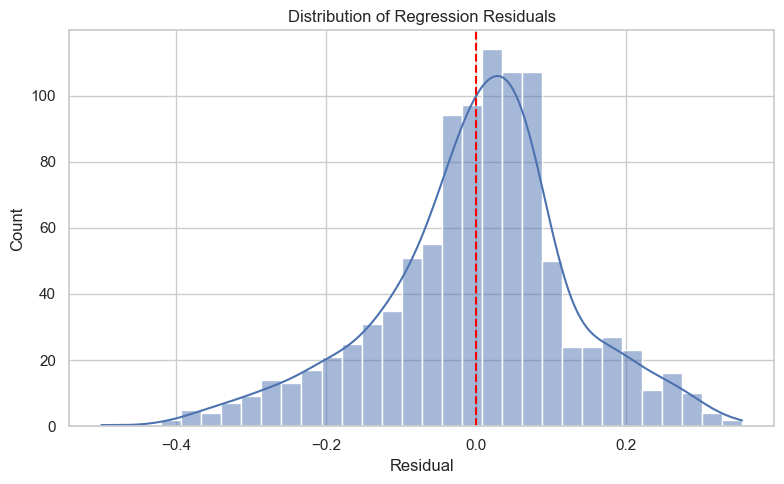

In [10]:
# Check the residual distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data["Residual"],
    kde=True
)

plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Residual")
plt.title("Distribution of Regression Residuals")
plt.tight_layout()
plt.show()

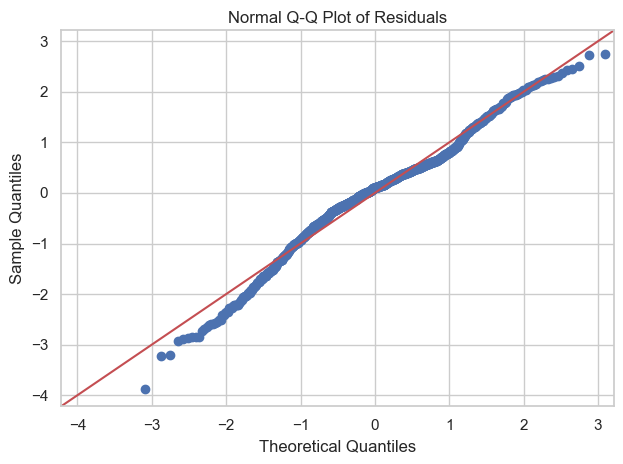

In [11]:
# Create a normal Q-Q plot

sm.qqplot(
    data["Residual"],
    line="45",
    fit=True
)

plt.title("Normal Q-Q Plot of Residuals")
plt.tight_layout()
plt.show()

In [12]:
# Test residual normality

shapiro_stat, shapiro_p = stats.shapiro(data["Residual"])

print("Shapiro-Wilk Statistic:", shapiro_stat)
print("P-value:", shapiro_p)

if shapiro_p < 0.05:
    print("Conclusion: Reject normality at the 5% significance level.")
else:
    print("Conclusion: Do not reject normality at the 5% significance level.")

Shapiro-Wilk Statistic: 0.9792167263947684
P-value: 9.308478147547563e-11
Conclusion: Reject normality at the 5% significance level.


In [13]:
# Check multicollinearity using VIF

X_vif = sm.add_constant(X)

vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# The intercept is not interpreted as a predictor VIF
vif_data = vif_data[vif_data["Feature"] != "const"]

print(vif_data.round(3))

             Feature    VIF
1          GRE Score  1.154
2        TOEFL Score  1.127
3  University Rating  1.186
4                SOP  1.211
5                LOR  1.212
6               CGPA  1.264
7           Research  1.104


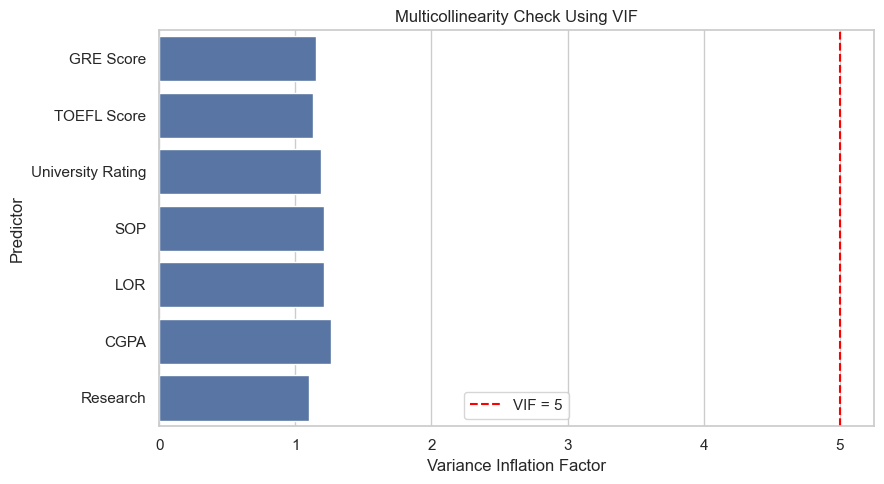

In [14]:
# Interpret the results

plt.figure(figsize=(9, 5))

sns.barplot(
    data=vif_data,
    x="VIF",
    y="Feature"
)

plt.axvline(5, color="red", linestyle="--", label="VIF = 5")
plt.xlabel("Variance Inflation Factor")
plt.ylabel("Predictor")
plt.title("Multicollinearity Check Using VIF")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
# Validate homoscedasticity

# Run the Breusch–Pagan test
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(
    model.resid,
    model.model.exog
)

print("Breusch-Pagan LM Statistic:", bp_lm)
print("LM Test P-value:", bp_lm_p)
print("F Statistic:", bp_f)
print("F Test P-value:", bp_f_p)

if bp_lm_p < 0.05:
    print("Conclusion: Evidence of heteroscedasticity.")
else:
    print("Conclusion: No statistically significant evidence of heteroscedasticity.")

Breusch-Pagan LM Statistic: 15.517905424677014
LM Test P-value: 0.029904909321713635
F Statistic: 2.233772351124953
F Test P-value: 0.029524161631566348
Conclusion: Evidence of heteroscedasticity.


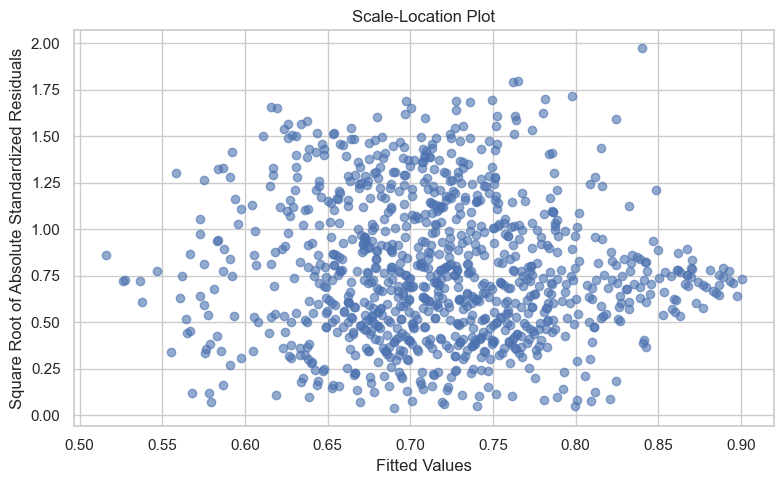

In [17]:
# Plot the scale-location relationship

fitted = model.fittedvalues
standardized_residuals = model.get_influence().resid_studentized_internal

scale_location = np.sqrt(np.abs(standardized_residuals))

plt.figure(figsize=(8, 5))

plt.scatter(
    fitted,
    scale_location,
    alpha=0.6
)

plt.xlabel("Fitted Values")
plt.ylabel("Square Root of Absolute Standardized Residuals")
plt.title("Scale-Location Plot")
plt.tight_layout()
plt.show()

In [ ]:
# # Use heteroscedasticity-robust standard errors

# robust_model = model.get_robustcov_results(cov_type="HC3")

# print(robust_model.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.221
Model:                            OLS   Adj. R-squared:                  0.215
Method:                 Least Squares   F-statistic:                     52.12
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           2.18e-63
Time:                        02:27:19   Log-Likelihood:                 631.06
No. Observations:                1000   AIC:                            -1246.
Df Residuals:                     992   BIC:                            -1207.
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.5316      0.12

Cook's Distance Threshold: 0.004
Potentially Influential Observations: 92


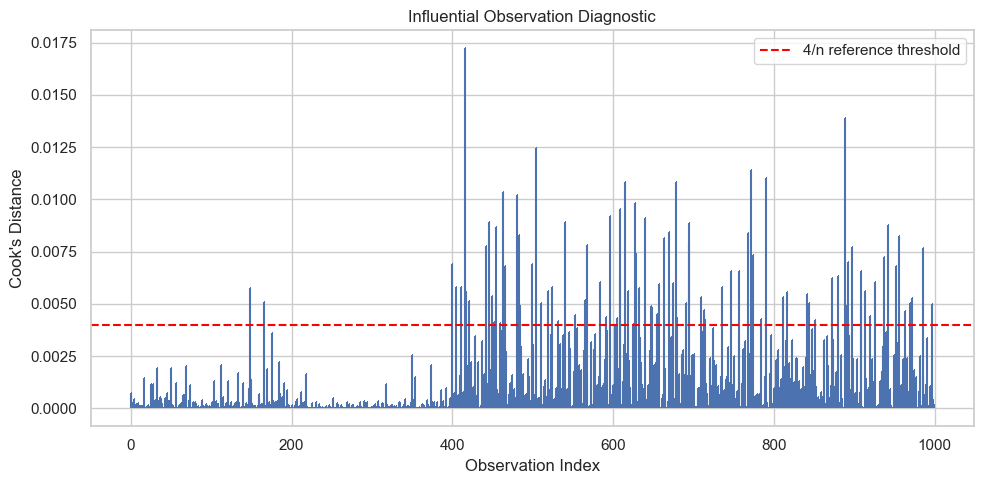

In [19]:
# Check potentially influential observations

influence = model.get_influence()

cooks_distance = influence.cooks_distance[0]

data["Cooks_Distance"] = cooks_distance

threshold = 4 / len(data)

print("Cook's Distance Threshold:", threshold)
print("Potentially Influential Observations:",
      (data["Cooks_Distance"] > threshold).sum())

plt.figure(figsize=(10, 5))

plt.stem(
    np.arange(len(data)),
    data["Cooks_Distance"],
    markerfmt=",",
    basefmt=" "
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="4/n reference threshold"
)

plt.xlabel("Observation Index")
plt.ylabel("Cook's Distance")
plt.title("Influential Observation Diagnostic")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Evaluate model performance on unseen data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Add intercepts separately to training and test data
X_train_ols = sm.add_constant(X_train, has_constant="add")
X_test_ols = sm.add_constant(X_test, has_constant="add")

# Fit on training data only
train_model = sm.OLS(y_train, X_train_ols).fit()

# Predict on the test data
y_pred = train_model.predict(X_test_ols)

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("Test R-squared:", round(r2, 4))
print("Test RMSE:", round(rmse, 4))
print("Test MAE:", round(mae, 4))

Test R-squared: 0.2096
Test RMSE: 0.122
Test MAE: 0.0908


In [24]:
# Generate the final diagnostic report

# Residual normality test
shapiro_stat, shapiro_p = stats.shapiro(model.resid)

# Homoscedasticity test
bp = het_breuschpagan(model.resid, model.model.exog)

# VIF summary
max_vif = vif_data["VIF"].max()

# Influence summary
influence = model.get_influence()
cooks_distance = influence.cooks_distance[0]
influential_count = int((cooks_distance > 4 / len(data)).sum())

print("ADVANCED REGRESSION DIAGNOSTIC REPORT")

print("\n1. MODEL PERFORMANCE")
print("Observations:", len(data))
print("R-squared:", round(model.rsquared, 4))
print("Adjusted R-squared:", round(model.rsquared_adj, 4))
print("In-sample RMSE:", round(np.sqrt(mean_squared_error(
    y, model.fittedvalues)), 4))
print("In-sample MAE:", round(mean_absolute_error(
    y, model.fittedvalues), 4))

print("\n2. RESIDUAL NORMALITY")
print("Shapiro-Wilk p-value:", f"{shapiro_p:.6g}")
print("Normality rejected:", shapiro_p < 0.05)

print("\n3. MULTICOLLINEARITY")
print("Maximum predictor VIF:", round(max_vif, 3))
print("VIF above 5:", int((vif_data["VIF"] > 5).sum()))

print("\n4. HOMOSCEDASTICITY")
print("Breusch-Pagan p-value:", f"{bp[1]:.6g}")
print("Evidence of heteroscedasticity:", bp[1] < 0.05)

print("\n5. INFLUENTIAL OBSERVATIONS")
print("Observations above 4/n:", influential_count)

print("\n6. HELD-OUT TEST PERFORMANCE")
print("Test R-squared:", round(r2_score(y_test, y_pred), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("Test MAE:", round(mean_absolute_error(y_test, y_pred), 4))


ADVANCED REGRESSION DIAGNOSTIC REPORT

1. MODEL PERFORMANCE
Observations: 1000
R-squared: 0.2208
Adjusted R-squared: 0.2153
In-sample RMSE: 0.1287
In-sample MAE: 0.0963

2. RESIDUAL NORMALITY
Shapiro-Wilk p-value: 9.30848e-11
Normality rejected: True

3. MULTICOLLINEARITY
Maximum predictor VIF: 1.264
VIF above 5: 0

4. HOMOSCEDASTICITY
Breusch-Pagan p-value: 0.0299049
Evidence of heteroscedasticity: True

5. INFLUENTIAL OBSERVATIONS
Observations above 4/n: 92

6. HELD-OUT TEST PERFORMANCE
Test R-squared: 0.2096
Test RMSE: 0.122
Test MAE: 0.0908
